# IT6117 — Day 3 Lab

**Student edition · 20 guided coding tutorials + 7 independent projects + 3 research and implementation challenges.**

**Aim:** Use data, model performance, decision curves, reporting and lifecycle evidence to make justified decisions about clinical AI. Every number in the independent scenarios is **illustrative**, not clinical evidence.

**Tutorials cover:** Part 1 (study design, reporting, evaluation) and Part 2 (deployment, drift, governance, human–AI workflow).

**How to work:** Run the setup cell below. Work through the 20 tutorials **one at a time**: read the task, replace the small `____________` gap(s) in the provided code, and run its check. Only a correct answer produces a **green “Correct”**, followed by the actual computed output and the clinical/scientific interpretation. For an incomplete or incorrect answer, the result and interpretation are not shown. An unfinished expression may raise a normal Python error: replace its blank before running it. 

**Projects and challenges:** These are independent code-and-decision exercises. Each includes the exact input data/functions to use, a supplied visualization, and a small output target. Internet or generative-AI coding help is permitted. For optional worked code after trying, uncomment `show_project_solution('P1')` or `show_challenge_solution('C1')` and run the printed example yourself.

**Important:**  Use `t1_solution()` through `t20_solution()` only if you want to see one possible completed code example. All predictions are educational, illustrative, not evidence for use on real patients.

In [ ]:
%pip install numpy pandas scikit-learn matplotlib scipy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 50.7 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 58.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 71.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 61.8 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 52.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 41.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 55.6 MB/s  0:00:00
Using cached setuptools-84.2.1-py3-none-any.whl (876 kB)
  Created wheel for panda: filename=panda-0.3.1-py3-none-any.whl size=7284 sha256=00d11d3f9e16af2c3f12276c21f1b4e48ee2f3ea33881c0964cf21cfc22202c5
  Stored in directory: /home/codespace/.cache/pip/w

In [5]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 46.7 MB/s  0:00:006m0:00:01

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
## Setup 
from day3_backend import *
from IPython.display import display

bundle = prediction_bundle()  # prebuilt, fixed internal
print(f"Ready: {len(diabetes)} teaching rows; {len(bundle['y_train'])} train / {len(bundle['y_test'])} test.")
print("Setup Completed 😀😁!")

Ready: 442 teaching rows; 309 train / 133 test.
Setup Completed 😀😁!


### Dataset and evidence limitations -read this before interpreting results

The supplied **diabetesteaching.CSV** has 442 records and 14 columns. `high_progression` is an **artificial binary label generated by thresholding the continuous `progression` score at 141**. The `region` labels are **not independently collected hospital sites**. The file does **not** specify a genuine future prediction horizon, intervention, clinical outcome definition, or deployment setting. Even when an internal held-out model obtains good metrics, it **cannot support a diagnosis, prognosis, 30-day risk, treatment recommendation, or clinical deployment**.

The notebook therefore has two evidence streams:

- **Supplied teaching rows:** descriptive analysis, internal train/test evaluation, threshold demonstration.
- **Clearly fictional mini-scenarios:** post-score leakage timelines, RCT counts, incoming drift, LLM audits, vendor/procurement situations.

A classroom threshold (0.40) is used for comparisons; it is not clinically justified. The model is a deliberately simple logistic-regression pipeline with train-only preprocessing and a fixed split, **not a validated clinical model**.

,record_id,region,age,sex,bmi,blood_pressure,serum_cholesterol,ldl,hdl,cholesterol_hdl_ratio,log_triglycerides,glucose,progression,high_progression
0,D2-001,Agder,59,M,32.1,101.0,157,93.2,38.0,4.0,4.8598,87,151,1
1,D2-002,Rogaland,48,F,21.6,87.0,183,103.2,70.0,3.0,3.8918,69,75,0
2,D2-003,Oslo,72,M,30.5,93.0,156,93.6,41.0,4.0,4.6728,85,141,1
3,D2-004,Innlandet,24,F,25.3,84.0,198,131.4,40.0,5.0,4.8903,89,206,1


,dataset_id,health_data_type,row_count,possible_lab_use
0,diabetes,clinical/laboratory tabular,442,hypothesis testing and supervised prediction
1,breast_cancer,clinical outcomes tabular,306,outcome classification
2,stroke,population risk factor tabular,43400,binary stroke classification
3,adhd200,phenotypic research tabular,222,cohort description and QC filtering
4,sepsis,care episode tabular,110204,length-of-stay and outcome modeling


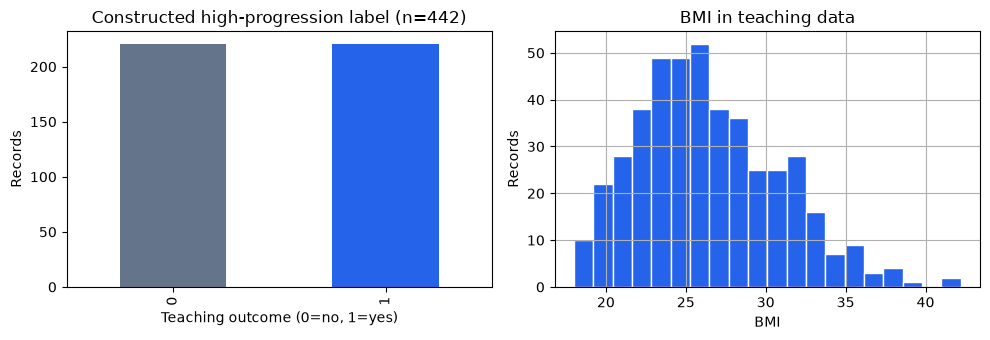

In [7]:
display(diabetes.head(4))
display(health_data_catalog[['dataset_id','health_data_type','row_count','possible_lab_use']])
plot_overview()

## Section A — Study design, time, reporting and validity
Begin with the clinical question and reporting scope, not an algorithm.

### Tutorial 1

**Task:** Find the proportion of the 442 teaching records labeled `high_progression = 1`. For a binary (0/1) column, `.mean()` gives that proportion. Complete the expression inside `round(..., 3)` using `diabetes['high_progression'].mean()`. The `3` means three decimal places.

**Example:** The mean of `[0, 1, 1, 0]` is `0.5`. **Output:** one number between 0 and 1.

In [9]:
answer = round(diabetes["high_progression"].mean(), 3)

t1_check(answer)

Answer: 0.5000
Interpretation: About 50.0% of supplied records have the constructed label; this is not disease prevalence or a prospective clinical event rate.


True

In [8]:
# View answer 
t1_solution()

answer = round(diabetes["high_progression"].mean(), 3)


### Tutorial 2

**Context:** An alert is generated on day 0. A measurement from day +2 is not available at that time. `feature_timeline` lists each variable and its `day_relative_to_score`.

**Task:** Complete the cut-off in the supplied `.loc` filter so only rows from **day 0 or earlier** are selected. The remaining code returns their `variable` names as a list. **Output:** a list of usable pre-score variable names.

In [11]:
before_score = feature_timeline.loc[feature_timeline["day_relative_to_score"] <= 0]
answer = before_score["variable"].tolist()

t2_check(answer)

Answer: ['age', 'bmi', 'blood_pressure', 'glucose']
Interpretation: These variables precede the fictional prediction time. Future records or outcomes would create temporal leakage. Availability in a real EHR must be verified.


True

In [10]:
# View answer (uncomment only if needed)
# t2_solution()

### Tutorial 3

**Context:** A test set must not reuse the same record IDs as the training set. `bundle['train_ids']` and `bundle['test_ids']` contain the two ID lists.

**Task:** The supplied code converts both to sets and computes the IDs found in both. Fill the blank with the existing variable whose **length** should be counted. **Example:** `{1, 2} ∩ {2, 3}` contains 1 ID. **Output:** an integer overlap count.

In [21]:
train_ids = set(bundle["train_ids"])
test_ids = set(bundle["test_ids"])
overlap = train_ids.intersection(test_ids)
answer = len(overlap)

t3_check(answer)

Answer: 0
Interpretation: Zero duplicate record IDs across the internal split is desirable, but does not demonstrate external transportability or rule out all forms of leakage.


True

In [19]:
# View answer (uncomment only if needed)
t3_solution()

train_ids = set(bundle["train_ids"])
test_ids = set(bundle["test_ids"])
overlap = train_ids.intersection(test_ids)
answer = len(overlap)


### Tutorial 4

**Context:** A model trained at Hospital A is evaluated, without retraining, on **labeled patients at Hospital B**. This asks about generalization to a new site not whether care outcomes improve. `STUDY_STAGES` maps scenario names to study-stage labels.

**Task:** Look up the supplied `scenario` variable in the `STUDY_STAGES` dictionary. **Output:** the name of the matching evidence stage (string).

In [18]:
scenario = "different_hospital_same_model"
answer = STUDY_STAGES[scenario]

t4_check(answer)

Answer: external_validation
Interpretation: A genuinely new hospital with independently collected outcomes permits external validation of a frozen model; it does not establish that AI-assisted care improves outcomes.


True

In [16]:
# View answer (uncomment only if needed)
t4_solution()

scenario = "different_hospital_same_model"
answer = STUDY_STAGES[scenario]


### Tutorial 5

**Context:** A retrospective prediction-model study needs a prediction-model reporting guideline. `STUDY_GUIDES` contains `objective` and `guideline` columns.

**Task:** The first line already selects the row for **Retrospective prediction model study**. Fill the **column name** needed to retrieve its guideline with `.iloc[0]`. **Output:** one reporting-guideline name (string).

In [22]:
rows = STUDY_GUIDES.loc[STUDY_GUIDES["objective"] == "Retrospective prediction model study"]
answer = rows["guideline"].iloc[0]

t5_check(answer)

Answer: TRIPOD+AI
Interpretation: TRIPOD+AI is a reporting guideline for prediction models. Complete reporting does not guarantee low bias; use PROBAST+AI for appraisal.


True

In [23]:
# View solution (uncomment only if needed)
t5_solution()

rows = STUDY_GUIDES.loc[STUDY_GUIDES["objective"] == "Retrospective prediction model study"]
answer = rows["guideline"].iloc[0]


### Tutorial 6

**Context:** A study report has several fields. A `None` value in `REPORT_FIELDS` means the field has not been specified.

**Task:** Finish the list comprehension (i.e., code inside []) so it returns the names of fields whose value **is Python `None`**. **Example:** `{'site':'A', 'horizon':None}` has one missing field: `['horizon']`. **Output:** a list of missing-field names in their original order.

In [24]:
answer = [name for name, value in REPORT_FIELDS.items() if value is None]

t6_check(answer)

Answer: ['horizon', 'independent_hospital']
Interpretation: Without an actual outcome horizon and independent-hospital evidence, do not claim a 30-day prognostic alert or readiness for deployment.


True

In [ ]:
# View solution (uncomment only if needed)
# t6_solution()

In [ ]:
# Held-out split was created by setup. No fit or evaluation on test rows here.
print('Internal split:', len(bundle['train_ids']), 'train records /', len(bundle['test_ids']), 'test records')

## Section B — Model evaluation, probabilities and decision curves

### Tutorial 7

**Context:** An alert is positive when risk is at least `THRESHOLD = 0.40`. `confusion_summary(y, p, threshold)` returns counts labeled `tp` (true positives), `fp` (false positives), `fn` (missed positives), and `tn` (true negatives).

**Task:** Select the dictionary key for **true positives**: patients with label 1 who also received an alert. The code already makes the confusion table. **Output:** an integer count.

In [26]:
counts = confusion_summary(bundle["y_test"], bundle["p_test"], THRESHOLD)
answer = counts["tp"]

t7_check(answer)

Answer: 56
Interpretation: At threshold 0.40, 56 alerts correctly identify constructed events, while 10 events are missed; verify both error types before considering an alert policy.


True

In [25]:
# View solution (uncomment only if needed)
t7_solution()

counts = confusion_summary(bundle["y_test"], bundle["p_test"], THRESHOLD)
answer = counts["tp"]


### Tutorial 8

**Context:** Sensitivity (i.e., recall, or `did we flag the bad events?`) tells us the fraction of actual events detected at threshold 0.40. Formula: **TP / (TP + FN)**, where TP = detected events and FN = missed events.

**Task:** The code already retrieves TP and FN from `confusion_summary`. Fill in the missing denominator term. **Output:** a proportion between 0 and 1.

In [27]:
counts = confusion_summary(bundle["y_test"], bundle["p_test"], THRESHOLD)
tp = counts["tp"]
fn = counts["fn"]
answer = tp / (tp + fn)

t8_check(answer)

Answer: 0.8485
Interpretation: 84.8% of constructed events are flagged; the rest are missed. Sensitivity depends on the threshold and does not quantify alert usefulness.


True

In [ ]:
# View solution (uncomment only if needed)
# t8_solution()

### Tutorial 9

**Context:** Positive predictive value (PPV) (i.e., precision, or `Is this alert actually real?`) tells us what fraction of **alerts** correspond to true events at threshold 0.40. FP = alerts without the event.

**Task:** The code already retrieves TP and FP. Fill in the numerator and denominator terms. Search the correct formula for PPV and solve the task yourself. **Output:** a proportion between 0 and 1.

In [30]:
counts = confusion_summary(bundle["y_test"], bundle["p_test"], THRESHOLD)
tp = counts["tp"]
fp = counts["fp"]
answer = tp / (tp + fp)

t9_check(answer)

Answer: 0.7089
Interpretation: 70.9% of 79 alerts correspond to constructed events; PPV is sensitive to event frequency and case mix.


True

In [29]:
# View solution (uncomment only if needed)
t9_solution()

counts = confusion_summary(bundle["y_test"], bundle["p_test"], THRESHOLD)
tp = counts["tp"]
fp = counts["fp"]
answer = tp / (tp + fp)


### Tutorial 10

**Context:** AUROC measures how well a model ranks event versus non-event records **across thresholds** (i.e., `regardless of our current alert settings, how good is the system's overall ability to tell the difference between a real event and noise?`). The prediction labels are `bundle['y_test']` and held-out probabilities are `bundle['p_test']`.

**Task:** Insert the appropriate imported metric **function name** in the provided call: `roc_auc_score`, `average_precision_score`, or `brier_score_loss`. Here you need **AUROC**. **Output:** one score between 0 and 1 (perfect); `a score of 0.5 is a pure guess`.

In [ ]:
answer = ____________(bundle["y_test"], bundle["p_test"])

t10_check(answer)

In [ ]:
# View solution (uncomment only if needed)
# t10_solution()

### Tutorial 11

**Context:** With relatively uncommon events, the precision–recall relationship helps describe how many alerts are useful. **Average precision** summarizes performance across alert thresholds.

**Task:** Complete the provided call using the imported metric function that calculates **average precision**: think and choose among `roc_auc_score`, `average_precision_score`, and `brier_score_loss`. Inputs are already supplied. **Output:** a score between 0 and 1.

In [ ]:
answer = ____________(bundle["y_test"], bundle["p_test"])

t11_check(answer)

In [ ]:
# View solution (uncomment only if needed)
# t11_solution()

### Tutorial 12

**Context:** AUROC evaluates ranking; a Brier score evaluates **probability error**. Its formula is the mean of `(predicted_probability − actual_outcome)²`, and **smaller is better**.

**Task:** This should be pretty easy for you. Complete the code and pick the matching imported functions from `roc_auc_score`, `average_precision_score`, and `brier_score_loss`. Labels and probabilities are already supplied. **Example:** For a true event with risk 0.8, squared error is `(0.8−1)² = 0.04`. 

In [ ]:
answer = ____________(bundle["____________"], bundle["____________"])

t12_check(answer)

In [ ]:
# View solution (uncomment only if needed)
# t12_solution()

### Tutorial 13

**Context:** A calibration table groups predictions into risk bands and reports both `mean_predicted` (average estimated risk) and `observed_rate` (fraction with the actual event). The helper `calibration_table` creates five bands, excluding empty ones.

**Task:** The starter code has selected the **first nonempty row**. Fill the column name for the **actual event fraction**, rather than average predicted risk. **Output:** a proportion between 0 and 1.

In [ ]:
bins = calibration_table(bundle["y_test"], bundle["p_test"])
first_bin = bins.iloc[0]
answer = first_bin["____________"]

t13_check(answer)

In [ ]:
# View solution (uncomment only if needed)
# t13_solution()

In [ ]:
# Optional visual review after finishing the related tutorials:
plot_evaluation()  # model metrics and decision curves
plot_threshold_tradeoff()  # alert workload at different thresholds

### Tutorial 14

**Context:** `subgroup_table` calculates model sensitivity for the illustrative groups `older` and `younger`. A group difference can be negative depending on subtraction order. Here we want its **size**, not its direction.

**Task:** The starter code retrieves the two sensitivity values. Fill in the Python function that makes the difference **nonnegative**. **Example:** 0.60 versus 0.80 produces an absolute gap of 0.20. **Output:** a gap between 0 and 1.

In [ ]:
groups = subgroup_table(bundle["y_test"], bundle["p_test"], bundle["age_group"])
older = groups.loc[groups["group"] == "older", "sensitivity"].iloc[0]
younger = groups.loc[groups["group"] == "younger", "sensitivity"].iloc[0]
answer = ____________(older - younger)

t14_check(answer)

In [ ]:
# View solution (uncomment only if needed)
# t14_solution()

### Tutorial 15

**Context:** A higher risk threshold usually sends fewer alerts. Here an alert means `bundle['p_test'] >= 0.60`; this threshold is **illustrative**, not a clinical recommendation. Comparing probabilities to a threshold produces `True` or `False` for every record.

**Task:** Complete the NumPy method that **counts True values** in `predicted_alerts`. The `int(...)` conversion is supplied. **Output:** number of alerts (integer).

In [ ]:
new_threshold = 0.60
predicted_alerts = bundle["p_test"] >= new_threshold
answer = int(predicted_alerts.____________())

t15_check(answer)

In [ ]:
# View solution (uncomment only if needed)
# t15_solution()

### Tutorial 16

**Context:** A decision curve ***(i.e., focus on real-world utility by asking `Does using this system to trigger alerts actually do more harm than good, and at what point is it worth taking action?`)*** compares clinical actions using **net benefit**, not AUROC. At risk threshold `t`, `net benefit = TP/N − (FP/N) × t/(1−t)`. `N` is the number of test records.

**Task:** The starter code already extracts `TP`, `FP`, `N`, and computes `penalty = t/(1−t)`. Supply the missing **false-positive proportion** in `TP/N − blank × penalty`. **Output:** a net-benefit value per person (can be negative).

In [ ]:
counts = confusion_summary(bundle["y_test"], bundle["p_test"], THRESHOLD)
TP, FP, N = counts["tp"], counts["fp"], counts["n"]
penalty = THRESHOLD / (1 - THRESHOLD)
answer = TP / N - ____________ * penalty

t16_check(answer)

In [ ]:
# View solution (uncomment only if needed)
# t16_solution()

### Tutorial 17

**Context:** A decision curve must also compare a model against **treat all** and **treat none**. For threshold `t`, `treat-all NB = prevalence − (1−prevalence)×t/(1−t)`. Treat-none NB is zero.

**Task:** The prevalence and numerator have already been supplied. Fill the missing threshold value in the denominator `1 − t`. Use the constant `THRESHOLD` (0.40), not a new number. **Output:** treat-all net benefit per person.

In [ ]:
prevalence = bundle["y_test"].mean()
answer = prevalence - (1 - prevalence) * ____________ / (1 - ____________)

t17_check(answer)

In [ ]:
# View solution (uncomment only if needed)
#t17_solution()

In [ ]:
# Optional visual review after finishing the related tutorials:
plot_evaluation()  # model metrics and decision curves
plot_threshold_tradeoff()  # alert workload at different thresholds

## Section C — Clinical impact, shift, and deployment monitoring

A usable score is a system comprising data, model, human, workflow, and safety owner.

### Tutorial 18

**Context:** Prediction accuracy is not evidence of improved patient outcomes. An **illustrative randomized trial** has 44 adverse events in 500 AI-assisted patients versus 60 in 500 usual-care patients.

**Task:** Compute **risk difference = AI event rate − usual-care event rate**. Both rates are already calculated. Fill the first term of the subtraction. **Output:** risk difference as a fraction, not a percent.

In [ ]:
ai_risk = ____________
usual_risk = ____________
answer = ____________ - ____________

t18_check(answer)

In [ ]:
# View solution (uncomment only if needed)
# t18_solution()

### Tutorial 19

**Context:** A fictional safety plan says to **pause affected scoring** when the incoming `glucose` missing-value fraction **exceeds 10%**. `triage_rule(missing_rate, max_missing=...)` implements this predefined rule.

**Task:** The incoming missingness is already calculated with `.isna().mean()`. Fill the maximum allowed missing fraction as a **decimal**, not a percentage string. **Example:** 10% = `0.10`. **Output:** an action label such as `pause_and_investigate` or `continue_monitored`.

In [ ]:
baseline, incoming = shift_scenario()
missing_rate = incoming["glucose"].isna().mean()
answer = triage_rule(____________, max_missing=____________)

t20_check(answer)

In [ ]:
# View solution (uncomment only if needed)
t20_solution()

In [ ]:
# Optional visual review after finishing the related tutorials:
plot_evaluation()  # model metrics and decision curves
plot_threshold_tradeoff()  # alert workload at different thresholds

## Seven independent projects

These projects let you **calculate a small result, interpret it, and make a practical health-AI decision**. The data are already in the notebook: you do **not** need to find a CSV or train another model. 

**Projects 1–5** use the supplied teaching data or fictional variations; 
**Projects 6–7** use small, entirely fictional scenarios.

For each project: **(1)** run the provided evidence/visualization cell; **(2)** write your own short Python analysis in the blank code cell; **(3)** record the requested result and decision in the Markdown cell. One table and **2–4 clear sentences** are enough unless otherwise stated. Use `display(...)`, `print(...)`, internet searches, or generative-AI coding assistance if helpful. After trying, the optional solution cell can print *one* worked coding approach (it does not execute the code). Every example is for teaching, not patient care.

### Project 1

**Case: Can we honestly call this a “30-day diabetes alert”?** A team proposes that label for the classroom model. However, `high_progression` is a **constructed teaching label**, and no real 30-day outcome was collected. An alert occurs on **day 0**: data from day +1 or later would be unavailable when scoring.

**Available data:** `feature_timeline` has `variable` and `day_relative_to_score` (`<= 0` means already available in this simplified example). `REPORT_FIELDS` is a dictionary of reporting details (`None` means unknown). `STUDY_GUIDES` links study objectives to reporting/appraisal guidelines. Run the next cell to inspect them.

**Your programming task:** (1) Make a two-column table showing each variable and **Allowed before/on day 0?**; (2) print the list of `REPORT_FIELDS` keys whose values are `None`. *Example of the rule:* day −1 is allowed; day +2 is excluded.

**Decision:** **Approve or hold the 30-day claim?** State which essential evidence is missing, name the prediction-model **reporting** guideline and the different **risk-of-bias appraisal** tool, and identify one next study step. Reporting a study well is not the same as proving it unbiased.

**Submit:** one small table, the missing-field list, and a **3-sentence** decision.

In [ ]:
display(feature_timeline)
print("Missing means unreported (None); it does NOT mean a zero-day horizon:")
display(pd.DataFrame([{"field": k, "value": str(v)} for k, v in REPORT_FIELDS.items()]))
print("Available study/reporting guidance:")
display(STUDY_GUIDES[["objective", "guideline", "purpose"]])

In [ ]:
# Write your own analysis here. Use the named inputs and functions above.
# Show a small table or figure that supports your final decision.

**P1 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: to print one possible solution for P1.
show_project_solution("P1")

### Project 2

**Case: Two models have the same AUROC—but should the hospital treat them as equivalent?** Fictional Model B changes Model A’s probabilities using a square root. A strictly increasing transformation preserves rankings (and hence AUROC) but changes the reported risks and alerts.

**Available data:** `model_comparison()` returns columns `y` (0=no event, 1=event), `model_A` and `model_B`. Use `roc_auc_score(y,p)`, `brier_score_loss(y,p)`, `confusion_summary(y,p,0.40)['alerts']` and `net_benefit(y,p,0.40)`. The next cell plots both probability scales.

**Your programming task:** Create **one row per model** with **AUROC, Brier score, number of alerts, net benefit** at the fixed illustrative threshold **0.40**. Lower Brier means lower average probability error; higher net benefit means a more favorable illustrative trade-off at that threshold.

**Decision:** Which model would you take **forward for independent evaluation**, and why? Explain why equal AUROC does not mean equal alert burden or clinical usefulness. Do **not** claim either model is fit for patient care.

**Submit:** a 2-row comparison table and **2–3 sentences** supporting the decision.

In [ ]:
plot_model_comparison()

In [ ]:
# Write your own analysis here. Use the named inputs and functions above.
# Show a small table or figure that supports your final decision.

**P2 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: to print one complete possible solution for P2.
show_project_solution("P2")

### Project 3

**Case: Good decision-curve performance, but too many alerts.** A ward can review **at most 50 alerts for 133 records**. The classroom score currently uses a **preselected threshold of 0.40**. Staff cannot safely act on extra alerts.

**Available data:** `bundle['y_test']` contains event labels and `bundle['p_test']` contains risks for **133 held-out teaching records**. `decision_curve(y,p,[...])` returns `threshold`, `model`, `treat_all`, `treat_none`, `alerts`. The graphs below show net benefit and workload.

**Your programming task:** For thresholds **0.40, 0.55, 0.60, 0.65**, make a table containing the five supplied quantities plus two Yes/No columns: **within capacity** (`alerts <= 50`) and **better than both defaults** (`model > treat_all` and `model > treat_none`). Here, *net benefit is not accuracy*; it balances true and false alerts at a specified harm trade-off.

**Decision:** Can the ward **deploy at 0.40 now**? If another threshold *appears* preferable in these test rows, explain why it must be chosen using clinical preferences and **separate** validation data—not tuned to this final test set.

**Submit:** one threshold table, a **go/hold** decision, and **two next steps**.

In [ ]:
plot_evaluation()
plot_threshold_tradeoff()

In [ ]:
# Write your own analysis here. Use the named inputs and functions above.
# Show a small table or figure that supports your final decision.

**P3 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: to print one complete possible solution for P3.
show_project_solution("P3")

### Project 4

**Case: Does a good overall score hide a group-level concern?** The teaching test set is split into `older` and `younger` groups for practice. These are **arbitrary median-based groups**, not medically meaningful age categories.

**Available data:** `subgroup_table(bundle['y_test'], bundle['p_test'], bundle['age_group'])` returns each group’s **n**, events, sensitivity, PPV, alerts and alert rate. Run the supplied bar chart.

**Your programming task:** Display the subgroup table. Calculate **sensitivity(older) − sensitivity(younger)**. *Example:* 0.80 − 0.60 = **0.20**, a difference of **20 percentage points** (illustrative example, not this dataset).

**Decision:** Is a difference in this small, artificial split enough to declare the model “fair” or “unfair”? State what additional subgroup validation and clinical/equity review would be necessary.

**Submit:** the table, one signed difference, and **2–3 sentences**. No bootstrap or advanced statistics required.

In [ ]:
plot_subgroups()

In [ ]:
# Write your own analysis here. Use the named inputs and functions above.
# Show a small table or figure that supports your final decision.

**P4 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: uncomment to print one possible solution for P4.
show_project_solution("P4")

### Project 5

**Case: The EHR changes and incoming measurements look different.** A simulated incoming data batch has more missing `glucose` values. **Current patient outcome labels are unavailable**. The fictional hospital has a predefined **quality gate: pause affected scoring when glucose missingness is strictly greater than 10%**.

**Available data:** `baseline, incoming = shift_scenario()` provides two DataFrames. `drift_report(baseline,incoming)` gives input distribution comparisons; `incoming['glucose'].isna().mean()` gives missingness; `triage_rule(missing_rate,max_missing=0.10)` returns the quality-gate recommendation. Review the drift and workflow visuals below.

**Your programming task:** Display the drift report. Print incoming missingness **as a percentage** and the action from `triage_rule`. *Example:* 0.12 means 12% missing and is over a 10% gate.

**Decision:** **Continue, pause/investigate or retrain automatically?** State one likely data-quality cause to check, who must own the clinical-safety decision, and one condition for restarting. Input drift alone does **not** prove that accuracy has fallen.

**Submit:** one drift table, the missing percentage and gate action, and **3–4 sentences**.

In [ ]:
plot_drift()
plot_system_workflow()
print('Fictional baseline and incoming records:',len(shift_scenario()[0]),len(shift_scenario()[1]))

In [ ]:
# Write your own analysis here. Use the named inputs and functions above.
# Show a small table or figure that supports your final decision.

**P5 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: to print one complete possible solution for P5.
show_project_solution("P5")

### Project 6

**Case: Did an AI intervention improve patient outcomes—not merely prediction?** A **fictional randomized comparison** reports **60 adverse events / 500 usual-care patients** and **44 adverse events / 500 AI-assisted patients**. A lower event rate is better. These are **made-up trial counts, not evidence from patients**.

**Available data:** `rct_counts()` lists the two groups, their `events` and `patients`. `risk_difference(ai_events,ai_n,control_events,control_n)` returns **AI risk minus usual-care risk**.

**Your programming task:** Calculate both event rates, **risk difference** (`AI rate − usual rate`) and **risk ratio** (`AI rate / usual rate`). For an easy uncertainty check, also calculate the approximate 95% interval for risk difference: `RD ± 1.96 * sqrt(pAI*(1-pAI)/500 + pUsual*(1-pUsual)/500)`. The next cell plots the event rates. *Example:* 20/100 = 0.20 = 20%.

**Decision:** Does the **approximate interval include 0**? What would these fictional numbers suggest, and why would a real, appropriately powered trial with safety outcomes still be necessary before claiming benefit?

**Submit:** a small table of rates, RD, RR and interval, plus **2–3 sentences**. Negative RD means fewer adverse events in the AI group.

In [ ]:
plot_rct()
display(rct_counts())

In [ ]:
# Write your own analysis here. Use the named inputs and functions above.
# Show a small table or figure that supports your final decision.

**P6 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: to print one complete possible solution for P6.
show_project_solution("P6")

### Project 7

**Case: An LLM may give a correct answer that still contains unsafe advice.** A **fictional audit of 12 cases** records three yes/no flags per answer: `clinically_correct`, `unsupported_claim`, and `unsafe_action` (**1 = yes**, **0 = no**). One answer can have multiple flags.

**Available data:** `synthetic_llm_audit()` returns these columns. The next cell shows the records and a bar chart. For a 0/1 column, the **mean is the fraction of cases flagged**.

**Your programming task:** Compute and display a 3-row table with the **rate and count** for each of the three flags. *Example:* 3 flagged answers out of 12 = 25%.

**Decision:** Should this assistant be allowed to take **autonomous clinical actions**, or restricted to reviewed output? Identify **three practical safeguards**, and name the LLM reporting guideline covered in the lecture.

**Submit:** the table and **3–4 sentences** describing the action policy and safeguards. These 12 cases do **not** establish real-world LLM safety.

In [ ]:
display(synthetic_llm_audit())
plot_llm()

In [ ]:
# Write your own analysis here. Use the named inputs and functions above.
# Show a small table or figure that supports your final decision.

**P7 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: to print one complete possible solution for P7.
show_project_solution("P7")

## Three independent decision challenges

These are **fictional but realistic hospital decisions**, with all numbers supplied in the notebook. **No diabetes CSV is required.** Each asks you to calculate simple evidence, make a defensible decision, and state what the hospital must do next. Run the small data-and-visualization cell, write code in the following blank cell, then fill in your decision. These are **not quizzes** and have no single prescribed wording: your decision must follow the stated safety rule and evidence. Direct links to a relevant guideline are provided, so extra web research is optional. A complete **possible coding solution and interpretation** can be displayed afterward with `show_challenge_solution('C1')`, `C2` or `C3`.

### Challenge 1

**Situation: Vendor procurement — “95% accuracy”**. A fictional sepsis-alert vendor tested **1,000 encounters**: **50 had sepsis** and **950 did not**. The vendor predicted **no sepsis in any encounter**, yet advertises 95% accuracy. The medical director suggests buying the system immediately.

**Your programming task:** Make a 1,000-item actual-outcome list/array (**50 ones, 950 zeros**) and a 1,000-item prediction array (**all zeros**). Compute **accuracy** = correct/1,000, **sensitivity** = detected sepsis/50, **specificity** = correctly non-sepsis/950, and **number of alerts** = predicted ones. Draw a bar chart comparing **accuracy vs sensitivity** (both on a 0–100% scale). If there are no positive predictions, **PPV is undefined**; do not divide by zero. *Example:* correctly flagging 8/10 actual cases gives 80% sensitivity.

**Decision:** **Buy/deploy or hold?** Give **three specific evidence requests** before reconsidering: e.g., prospective prediction timing and labels, independent-hospital results, or false-alert/missed-case analysis. Cite this provided reporting reference (no searching required): [TRIPOD+AI, BMJ 2024](https://www.bmj.com/content/385/bmj-2023-078378).

**Submit:** the 4 numerical results, PPV status, **one accuracy/sensitivity bar chart**, and **3–5 decision sentences**. The vendor data are fictional.

In [ ]:
plot_vendor_trap()
print('Scenario facts: 1000 encounters; 50 positives; predicted positives = 0; no real hospital data.')

In [ ]:
# Write your own analysis here. Use the named inputs and functions above.
# Show a small table or figure that supports your final decision.

**C1 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: uncomment to print one complete possible coding solution for C1.
show_challenge_solution("C1")

### Challenge 2

**Situation: Supervised pilot — does the ward actually respond to AI alerts?** A fictional hospital is testing a human-reviewed AI alert in a **small supervised pilot**. Alerts are visible to clinicians. Over **three weeks**, the table below gives patient encounters, alert counts, alerts reviewed within 30 minutes, and software failures.

**The hospital set two rules *before* the pilot:** (1) **At least 90% of all alerts must be reviewed within 30 minutes**; (2) there must be **zero software failures** before the pilot can be expanded. These are **fictional example gates**, not universal medical standards. This is a **pilot**, not a silent trial: in a silent trial clinicians do not act on hidden model predictions.

**Your programming task:** Use the provided DataFrame `pilot_data`. Calculate **timely review percentage in each week** (`timely / alerts × 100`), **overall timely percentage** (`total timely / total alerts × 100`), and **total software failures**. Create a small summary table. The next cell plots the weekly review rates and the 90% requirement. *Example:* 9 on-time reviews out of 10 alerts = 90%.

**Decision:** **Expand the pilot or hold and fix the workflow?** Explain which rules pass/fail, identify **one likely human-workflow improvement** and **one technical check**, and name the role who should approve restarting. An apparently good prediction score **cannot demonstrate patient benefit**.

**Submit:** the weekly table, two overall numbers, and **3–5 decision sentences**. Optional reading: [DECIDE-AI reporting for early live evaluations](https://www.bmj.com/content/377/bmj-2022-070904).

In [ ]:
# Fictional supervised-pilot records. All numbers needed for Challenge 2 are below.
pilot_data = pd.DataFrame({
    "week": ["Week 1", "Week 2", "Week 3"],
    "encounters": [100, 100, 100],
    "alerts": [20, 25, 30],
    "reviewed_within_30min": [18, 21, 22],
    "software_failures": [0, 1, 0],
})
display(pilot_data)
fig, ax = plt.subplots(figsize=(7, 3.3))
review_percent = 100 * pilot_data["reviewed_within_30min"] / pilot_data["alerts"]
ax.bar(pilot_data["week"], review_percent)
ax.axhline(90, color="black", linestyle="--", label="Required ≥90%")
ax.set(ylabel="Alerts reviewed within 30 min (%)", title="Pilot alert review timeliness (fictional)", ylim=(0, 105))
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Independent analysis: use pilot_data displayed above.
# Calculate each week's timely %, the overall %, and total software failures.
# Display your small summary table and compare with the two pilot gates.

**C2 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: uncomment to print one complete possible coding solution for C2.
# show_challenge_solution("C2")

### Challenge 3

**Situation: Post-deployment safety incident — can the hospital safely keep scoring?** After a fictional EHR interface upgrade, **200 incoming records** include **35 missing glucose values**, compared with **4 missing values in 200 records** before the upgrade. System logs also show **7 generated alerts were not delivered to clinicians** after the change, versus **none** before it. The model code is unchanged. **Current clinical outcome labels are unavailable.**

**The hospital's pre-agreed incident rules:** **pause the affected AI alert service** if glucose missingness is **over 10%** *or* **any generated alert fails delivery**. These are conservative example rules for this exercise, not general regulatory thresholds.

**Your programming task:** Using the supplied `incident_data` table, calculate **before and after glucose missing percentages**, the **increase in percentage points**, and the number of **undelivered alerts after the upgrade**. Display a small comparison table and refer to the supplied bar chart. *Example:* 10/100 = 10%; 18% − 10% = +8 percentage points.

**Incident decision:** **Continue, pause/rollback, or automatically retrain the model?** Identify **a named accountable role** (e.g., clinical safety lead), **two measurable restart conditions** for data and alert delivery, and the response sequence: detect → investigate → protect patients → communicate → revalidate. Explain why working model code and missing outcome labels do not prove safety.

**Submit:** one comparison table and **4–6 short decision sentences**. Reference: [FUTURE-AI trustworthy deployment consensus, BMJ 2025](https://www.bmj.com/content/388/bmj-2024-081554).

In [ ]:
# Fictional post-upgrade incident: standalone counts, no external dataset required.
incident_data = pd.DataFrame({
    "period": ["Before upgrade", "After upgrade"],
    "records": [200, 200],
    "missing_glucose": [4, 35],
    "undelivered_alerts": [0, 7],
})
display(incident_data)
fig, ax = plt.subplots(figsize=(7, 3.3))
missing_percent = 100 * incident_data["missing_glucose"] / incident_data["records"]
ax.bar(incident_data["period"], missing_percent)
ax.axhline(10, color="black", linestyle="--", label="Pause gate >10%")
ax.set(ylabel="Records with missing glucose (%)", title="EHR upgrade: missing data (fictional)", ylim=(0, 22))
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Independent analysis: use incident_data displayed above.
# Calculate both missing percentages, their percentage-point change,
# and the after-upgrade undelivered alert count. Show a comparison table.

**C3 — My result and decision**

*Write your short conclusion here. Refer to the numbers and chart/table generated above, and state one next step.*

In [ ]:
# Optional: uncomment to print one complete possible coding solution for C3.
show_challenge_solution("C3")

## For Your Information Only: Evidence-to-decision checklist

Before a final health-AI go/no-go recommendation, make sure your result contains all applicable elements:

| Dimension | Evidence to record | Unacceptable shortcut |
|---|---|---|
| **Purpose/design** | Patient population, prediction time, outcome and follow-up horizon, decision/action | “95% accuracy means benefit” |
| **Validity** | Source, timing/leakage, internal vs new-site tests, uncertain labels | “Random split = external validation” |
| **Reporting and bias** | TRIPOD+AI/STARD-AI/CONSORT-AI/TRIPOD-LLM as applicable; PROBAST+AI appraisal | Reporting completeness = low bias |
| **Prediction** | Sensitivity, PPV, AUROC/AP, Brier/calibration, subgroup uncertainty | AUROC alone |
| **Clinical action** | Prespecified clinical threshold, relative harms, net benefit vs both defaults, workload | Threshold tuned on final test set |
| **Impact** | Human–AI behavior, adverse events, patient outcomes, causal prospective study when claiming benefit | Simulation demonstrates patient benefit |
| **Deployment** | Responsible owner, EHR integration, human review, logs, monitoring, incident response and rollback | Unmonitored automatic retraining |

**Clinical use is out of scope:** the sample data, threshold, RCT and LLM examples are constructed teaching evidence only.

## Submission

**Suggested lab submission:** one executed notebook with the 20 tutorial check outputs, written analysis cells for 7 projects, and decision memos for 3 challenges; include plots, plain-language limitations, and any URLs consulted. Re-run the notebook from a fresh kernel before submitting.